## MULTI-seq demultiplexing for run 'multi_bAllos_4'


This is an example of the demultiplexing approach used for separating cells that belong to different samples labelled with separate MULTI-seq barcodes.  
The 

In [21]:
#devtools::install_github('chris-mcginnis-ucsf/MULTI-seq')

library(deMULTIplex)

library(KernSmooth)
library(reshape2)
library(Rtsne)
library(stringdist)
library(ShortRead)

library(ggplot2)
library(dplyr)
library(DescTools)

source("../sc_analysis_palettes_and_helpers.r")

# set working directory

outwd <- "data/"

## For primary tumour sample S1

### Pre-process sample barcode reads

In [6]:
# set sample name variable
dat_name <- "multi_bAllos_4_tums_s1"

In [8]:
# Read in cell barcodes written out from notebook "MULTI_seq_demux_prep.ipynb"
cell_bcs <- read.delim("/data/barcodes_after_filter_multi_bAllos_4_PTs_S1.txt", stringsAsFactors = F)

cell.id.vec <- cell_bcs$x
cell.id.vec.min <- substr(cell.id.vec,1,16)

In [7]:
# Provide sample barcode sequences used

bar.ref <- c(
            'CGACCAGC',
            'TTAGCCAG',
            'CCAACCGG',
            'TGACCGAT',
            'GCAACGCC',
            'CAATCGGT',
            'ATAGCGTC',
            'GAATCTCG',
            'AGACCTTG',
            'GAAGGAAG',
            'AGAAGAGG'
            )

In [ ]:
# Pre-process MULTI-seq sample barcode FASTQs
readTable <- MULTIseq.preProcess(R1 = c('/data/bAllos4_LMO_libs/bAllos4_tums_S1_LMO_S1_R1_001.fastq.gz'),
                                 R2 = c('/data/bAllos4_LMO_libs/bAllos4_tums_S1_LMO_S1_R2_001.fastq.gz'),
                                 cellIDs = cell.id.vec.min, cell=c(1,16), umi=c(17,28), tag=c(1,8))

write.csv(readTable, paste0(outwd,"readTable_",dat_name,".csv"), quote = F)


In [ ]:
# Perform MULTI-seq sample barcode alignment
readTable <- read.csv(paste0(outwd,"readTable_multi_bAllos_4_tums_s1.csv"), row.names = 1, stringsAsFactors = F)

bar.table <- MULTIseq.align(readTable, cell.id.vec.min, bar.ref)

write.csv(bar.table, paste0(outwd,"bar.table_",dat_name,".csv"), quote = F)


In [ ]:
# Visualize cells in barcode space on TSNE

bar.tsne <- barTSNE(bar.table[,1:11])
## Note: Exclude columns e.g. 9:10, if 8 barcodes were used, which provide total barcode UMI counts for each cell. 

pdf(paste0(outwd,"/pics/bc.check_",dat_name,".pdf"))
    for (i in 3:ncol(bar.tsne)) {
        g <- ggplot(bar.tsne, aes(x = TSNE1, y = TSNE2, color = bar.tsne[,i])) +
        geom_point() +
        scale_color_gradient(low = "black", high = "red") +
        ggtitle(colnames(bar.tsne)[i]) +
        theme(legend.position = "none") 
        print(g)
    }
dev.off()

### Classify cells

#### 1. deMULTIplex workflow

In [ ]:
# reload barcode-cell count matrix

bar.table <- read.csv(paste0(outwd, "bar.table_multi_bAllos_4_tums_s1.csv", row.names = 1, stringsAsFactors = F))


In [ ]:

## Round 1 -----------------------------------------------------------------------------------------------------
## Perform Quantile Sweep
bar.table.full <- bar.table[,1:11]
#good.bars <- paste("Bar",c(1:11,14:15),sep="")
#bar.table <- bar.table.full[, good.bars]  # Remove missing bars and summary columns
bar.table <- bar.table.full
bar.table_sweep.list <- list()
n <- 0
for (q in seq(0.01, 0.99, by=0.02)) {
  print(q)
  n <- n + 1
  bar.table_sweep.list[[n]] <- classifyCells(bar.table, q=q)
  names(bar.table_sweep.list)[n] <- paste("q=",q,sep="")
}

## Identify ideal inter-maxima quantile to set barcode-specific thresholds
threshold.results1 <- findThresh(call.list=bar.table_sweep.list)


In [ ]:
#png(paste0("pics/intMaxQuantile_",dat_name,".png"), width = 13, height = 15, units = 'in', res = 300)
  ggplot(data=threshold.results1$res, aes(x=q, y=Proportion, color=Subset)) + geom_line() + theme(legend.position = "left") +
  geom_vline(xintercept=threshold.results1$extrema, lty=2) + scale_color_manual(values=c("red","black","blue"))
#dev.off()

## Check the plot!! If it doesn't resemble the plot in the example found here (https://github.com/chris-mcginnis-ucsf/MULTI-seq), there may be missing barcodes remaining.

## Finalize round 1 classifications, remove negative cells
round1.calls <- classifyCells(bar.table, q=findQ(threshold.results1$res, threshold.results1$extrema))
neg.cells <- names(round1.calls)[which(round1.calls == "Negative")]
bar.table <- bar.table[-which(rownames(bar.table) %in% neg.cells), ]

print(length(neg.cells))
# In this round, 2850 negative cells were found and removed.


In [ ]:
## Round 2 (and repeat for following rounds) ---------------------------------------------------------------------

# Note that this cell is manually executed multiple times depending on the number of rounds needed.
# Prior to executing, set number of round for plot labelling
# Record number of negative cells identified per round in the following cell!

sweep_it <- 3

bar.table_sweep.list <- list()
n <- 0
for (q in seq(0.01, 0.99, by=0.02)) {
  print(q)
  n <- n + 1
  bar.table_sweep.list[[n]] <- classifyCells(bar.table, q=q)
  names(bar.table_sweep.list)[n] <- paste("q=",q,sep="")
}

threshold.results2 <- findThresh(call.list=bar.table_sweep.list)

png(paste0(outwd, "pics/intMaxQuantile_",dat_name,"_round",sweep_it,".png"), width = 13, height = 15, units = 'in', res = 300)
  ggplot(data=threshold.results2$res, aes(x=q, y=Proportion, color=Subset)) + geom_line() + theme(legend.position = "left") +
  geom_vline(xintercept=threshold.results2$extrema, lty=2) + scale_color_manual(values=c("red","black","blue"))
dev.off()

print(length(neg.cells))

round2.calls <- classifyCells(bar.table, q=findQ(threshold.results2$res, threshold.results2$extrema))
neg.cells <- c(neg.cells, names(round2.calls)[which(round2.calls == "Negative")])
bar.table <- bar.table[-which(rownames(bar.table) %in% neg.cells), ]

print(length(neg.cells))


Re-run previous cell until all no negative cells remain.  
**In this case it took 3 rounds**.
- In round two, another 513 negative cells were found.
- In round three, no additional negative cells were found.

In [ ]:
# finalize and save classification

final.calls <- c(round2.calls, rep("Negative",length(neg.cells)))
names(final.calls) <- c(names(round2.calls),neg.cells)
final.calls.dat <- as.data.frame(final.calls)
rownames(final.calls.dat) <- c(names(round2.calls),neg.cells)

# write
write.csv(final.calls.dat, paste0(outwd,"final.calls_",dat_name,".csv"), quote = F)


length(final.calls.dat$final.calls[final.calls.dat$final.calls == "Negative"]) # = 3363
length(final.calls.dat$final.calls[final.calls.dat$final.calls == "Doublet"]) # = 2445
length(final.calls.dat$final.calls[!final.calls.dat$final.calls %like any% c("Doublet","Negative")]) # = 10681


##### Semi-supervised negative cell reclassification

In [ ]:
# re-load the original input barcode-cell count matrix
bar.table <- read.csv(paste0(outwd,"bar.table_multi_bAllos_4_tums_s1.csv"), row.names = 1, stringsAsFactors = F)
# only keep barcode columns
bar.table.full <- bar.table[,1:11]

# Load classification results gained from deMULTIplex pipeline
## Load deMULTIplex classification results
final.calls.dat <- read.csv(paste0(outwd, "final.calls_multi_bAllos_4_tums_s1.csv"), stringsAsFactors = F, row.names = 1)
final.calls <- final.calls.dat$final.calls
final.calls <- as.character(final.calls)
names(final.calls) <- rownames(final.calls.dat)

## Perform semi-supervised negative cell reclassification
reclass.cells <- findReclassCells(bar.table.full, names(final.calls)[which(final.calls=="Negative")])
reclass.res <- rescueCells(bar.table.full, final.calls, reclass.cells)

## Visualize Results
png(paste0(outwd,"pics/classStab_",dat_name,"_round.png"), width = 13, height = 12, units = 'in', res = 300)
    print(ggplot(reclass.res[-1, ], aes(x=ClassStability, y=MatchRate_mean)) + 
        geom_point() + xlim(c(nrow(reclass.res)-1,1)) + 
        ylim(c(0,1.05)) +
        geom_errorbar(aes(ymin=MatchRate_mean-MatchRate_sd, ymax=MatchRate_mean+MatchRate_sd), width=.1) +
        geom_hline(yintercept = reclass.res$MatchRate_mean[1], color="red") +
        geom_hline(yintercept = reclass.res$MatchRate_mean[1]+3*reclass.res$MatchRate_sd[1], color="red",lty=2) +
        geom_hline(yintercept = reclass.res$MatchRate_mean[1]-3*reclass.res$MatchRate_sd[1], color="red",lty=2) +
        theme_bw()
    )
dev.off()

In [ ]:
# Set a class stability cut-off value based on the plot above. Then finalize negative cell rescue results

class_stab_val <- 17

final.calls.rescued <- final.calls
rescue.ind <- which(reclass.cells$ClassStability >= class_stab_val)
print(length(rescue.ind)) ## 9 negative cells could be reclassified
final.calls.rescued[rownames(reclass.cells)[rescue.ind]] <- reclass.cells$Reclassification[rescue.ind]

write.csv(final.calls.rescued, paste0(outwd,"final.calls.rescued_",dat_name,".csv"))

#### 2. Manual tresholding

In [27]:
# Start the second approach for classification from the original cell-barcode count matrix.
bar.table <- read.csv(paste0(outwd, "bar.table_multi_bAllos_4_tums_s1.csv"), row.names = 1, stringsAsFactors = F)

# only keep barcode columns
bar.table.full <- bar.table[,1:11]

# plot distribution of barcode counts across cells
bar.table.plot <- bar.table.full[,1:11]
bar.table.full <- as.data.frame(log2(bar.table.plot))
    for (i in 1:ncol(bar.table.plot)) {
        ind <- which(is.finite(bar.table.full[, i]) == FALSE)
        bar.table.full[ind, i] <- 0
        bar.table.full[, i] <- bar.table.full[, i] - mean(bar.table.full[, 
            i])
    }


for(i in 1:ncol(bar.table.full)){
  png(paste0(outwd,"pics/barhist_allBCs_",dat_name, "_BC_",i,".png"), width = 13, height = 15, units = 'in', res = 300)
    print(ggplot(bar.table.full) +
    geom_histogram(aes(x = bar.table.full[,i]), binwidth = 0.1, fill = "grey", color = "black") +
    scale_x_continuous(breaks = seq(-10, 10, 0.5)) +
    labs(x = paste0(colnames(bar.table.full)[i])) +
    theme_bw()
    )
  dev.off()
}

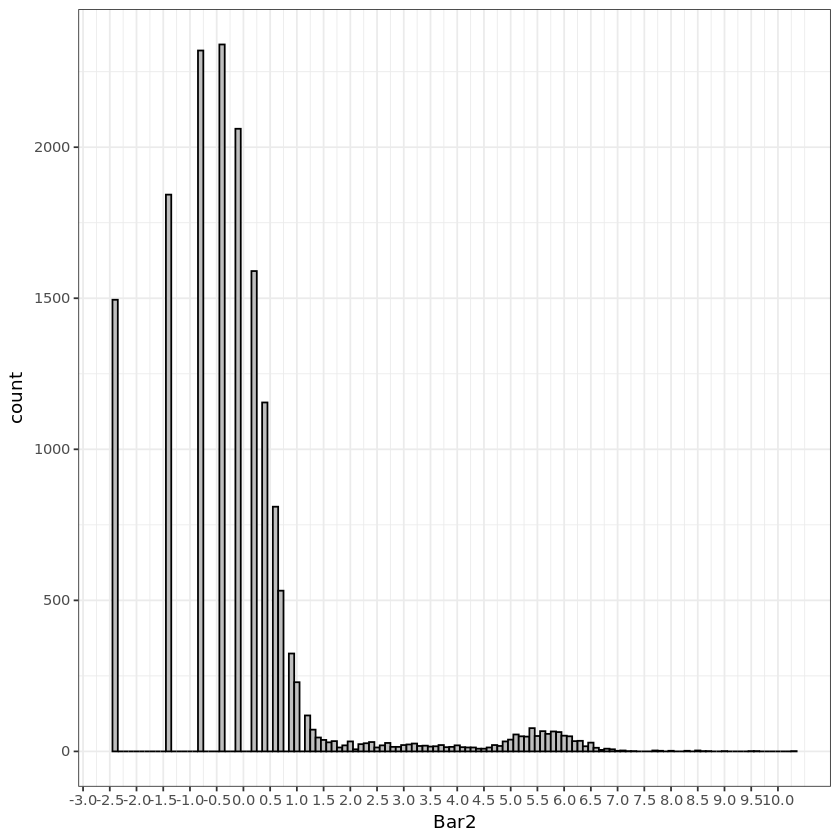

In [30]:
# one example plot in-line

i <- 2

ggplot(bar.table.full) +
    geom_histogram(aes(x = bar.table.full[,i]), binwidth = 0.1, fill = "grey", color = "black") +
    scale_x_continuous(breaks = seq(-10, 10, 0.5)) +
    labs(x = paste0(colnames(bar.table.full)[i])) +
    theme_bw()

In [31]:
# Determine manual cut-offs determining how many barcode molecules are needed for a cell to be classified positive for that barcode.

x1 <- 2.5
x2 <- 2.5
x3 <- 2.5
x4 <- 1.9
x5 <- 2.8
x6 <- 2.4
x7 <- 2.8
x8 <- 2.5
x9 <- 2.4
x10 <- 2.3
x11 <- 3.0

threshs <- c(x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11)

# Assign identities to cells
bar.table.full$Ident_act <- 0
bar.table.full$Ident <- 0
for(i in 1:11){
  bar.table.full$Ident_act <- 0
  bar.table.full$Ident_act[bar.table.full[,i] >= threshs[i]] <- i
  bar.table.full$Ident <- bar.table.full$Ident + bar.table.full$Ident_act
  bar.table.full$Ident[bar.table.full$Ident > i] <- 20
}

bar.table.full$class <- 0
bar.table.full$class[bar.table.full$Ident > 19] <- "Doublet"
bar.table.full$class[bar.table.full$Ident == 0] <- "Negative"
bar.table.full$class[bar.table.full$Ident == 1] <- "1"
bar.table.full$class[bar.table.full$Ident == 2] <- "2"
bar.table.full$class[bar.table.full$Ident == 3] <- "3"
bar.table.full$class[bar.table.full$Ident == 4] <- "4"
bar.table.full$class[bar.table.full$Ident == 5] <- "5"
bar.table.full$class[bar.table.full$Ident == 6] <- "6"
bar.table.full$class[bar.table.full$Ident == 7] <- "7"
bar.table.full$class[bar.table.full$Ident == 8] <- "8"
bar.table.full$class[bar.table.full$Ident == 9] <- "9"
bar.table.full$class[bar.table.full$Ident == 10] <- "10"
bar.table.full$class[bar.table.full$Ident == 11] <- "11"

bar.table.full$class <- as.character(bar.table.full$class)

In [32]:
# Overview of classification outcome:
for(i in 1:11){
  i <- as.character(i)
  print(paste0(length(bar.table.full$class[bar.table.full$class == i])," cells belong to class ",i))
  if(i == 1){
  sum_singlets <- length(bar.table.full$class[bar.table.full$class == i])
  }else{
  sum_singlets <- sum_singlets + length(bar.table.full$class[bar.table.full$class == i])
  }
  if(i == 11){
    print(paste0(sum_singlets, " barcodes were determined to be singlets."))
  }
}


[1] "701 cells belong to class 1"
[1] "1013 cells belong to class 2"
[1] "703 cells belong to class 3"
[1] "1675 cells belong to class 4"
[1] "615 cells belong to class 5"
[1] "925 cells belong to class 6"
[1] "703 cells belong to class 7"
[1] "695 cells belong to class 8"
[1] "891 cells belong to class 9"
[1] "1305 cells belong to class 10"
[1] "452 cells belong to class 11"
[1] "9678 barcodes were determined to be singlets."


In [ ]:
# Combine this classification with deMULTI-plex-based classification and write to file.

# Re-load original barcode-cell count matrix
bar.table <- read.csv(paste0(outwd,"bar.table_multi_bAllos_4_tums_s1.csv"), row.names = 1, stringsAsFactors = F)

# Re-oad deMULTIplex classification results
final.calls.dat <- read.csv(paste0(outwd,"final.calls_multi_bAllos_4_tums_s1.csv"), stringsAsFactors = F, row.names = 1)
final.calls <- final.calls.dat$final.calls
final.calls <- as.character(final.calls)
names(final.calls) <- rownames(final.calls.dat)

# Combine the manual classifications with the algorithm classified cells
bar.table.full$class <- as.character(bar.table.full$class)

final.calls.dat.plus <- merge(final.calls.dat,bar.table.full[,13:14], all.x = T, by = "row.names")
final.calls.dat.plus$final.calls <- as.character(final.calls.dat.plus$final.calls)

final.calls.dat.plus$class[final.calls.dat.plus$class %in% c("1")] <- "Bar1"
final.calls.dat.plus$class[final.calls.dat.plus$class %in% c("2")] <- "Bar2"
final.calls.dat.plus$class[final.calls.dat.plus$class %in% c("3")] <- "Bar3"
final.calls.dat.plus$class[final.calls.dat.plus$class %in% c("4")] <- "Bar4"
final.calls.dat.plus$class[final.calls.dat.plus$class %in% c("5")] <- "Bar5"
final.calls.dat.plus$class[final.calls.dat.plus$class %in% c("6")] <- "Bar6"
final.calls.dat.plus$class[final.calls.dat.plus$class %in% c("7")] <- "Bar7"
final.calls.dat.plus$class[final.calls.dat.plus$class %in% c("8")] <- "Bar8"
final.calls.dat.plus$class[final.calls.dat.plus$class %in% c("9")] <- "Bar9"
final.calls.dat.plus$class[final.calls.dat.plus$class %in% c("10")] <- "Bar10"
final.calls.dat.plus$class[final.calls.dat.plus$class %in% c("11")] <- "Bar11"

rownames(final.calls.dat.plus) <- final.calls.dat.plus$Row.names
final.calls.dat.plus$Row.names <- NULL
final.calls.dat.plus$Ident_act <- NULL
final.calls.dat.plus$Ident <- NULL

write.csv(final.calls.dat.plus, paste0(outwd,"final.calls.plus.manual_",dat_name,".csv"))


#### 3. Dominant barcode workflow

In [38]:
# Re-load original barcode-cell count matrix
bar.table <- read.csv(paste0(outwd,"bar.table_multi_bAllos_4_tums_s1.csv"), row.names = 1, stringsAsFactors = F)
bar.table.full <- bar.table


In [39]:
cell_class_2 <- vector("character", length = nrow(bar.table.full))
names(cell_class_2) <- rownames(bar.table.full)

In [37]:
cell_class_2 <- vector("character", length = nrow(bar.table.full))
names(cell_class_2) <- rownames(bar.table.full)


for(i in 1:nrow(bar.table)){
  if(max(bar.table[i,1:11]) > (bar.table[i,"nUMI"]*0.4)  && max(bar.table[i,1:11]) > (sort(bar.table[i,1:11], TRUE)[2] * 2.3)){
    cell_class_2[i] <- colnames(bar.table)[match(max(bar.table[i,1:11]),bar.table[i,])]
  }else if(bar.table[i,"nUMI"] > mean(bar.table$nUMI)){
    cell_class_2[i] <- "Doublet"
  }else{
    cell_class_2[i] <- "Negative"
  }
}


# Print assignments
length(cell_class_2[cell_class_2 != "Negative"])
for(i in 1:11){
    print(
        length(cell_class_2[cell_class_2 == paste0("Bar",i)])
    )
}
length(cell_class_2[cell_class_2 == "Doublet"])


#write.csv(cell_class_2, paste0(outwd,"final.calls.plus.domBC_2_",dat_name,".csv"))


Warning message in xtfrm.data.frame(x):
“cannot xtfrm data frames”
Warning message in xtfrm.data.frame(x):
“cannot xtfrm data frames”
Warning message in xtfrm.data.frame(x):
“cannot xtfrm data frames”
Warning message in xtfrm.data.frame(x):
“cannot xtfrm data frames”
Warning message in xtfrm.data.frame(x):
“cannot xtfrm data frames”
Warning message in xtfrm.data.frame(x):
“cannot xtfrm data frames”
Warning message in xtfrm.data.frame(x):
“cannot xtfrm data frames”
Warning message in xtfrm.data.frame(x):
“cannot xtfrm data frames”
Warning message in xtfrm.data.frame(x):
“cannot xtfrm data frames”
Warning message in xtfrm.data.frame(x):
“cannot xtfrm data frames”
Warning message in xtfrm.data.frame(x):
“cannot xtfrm data frames”
Warning message in xtfrm.data.frame(x):
“cannot xtfrm data frames”
Warning message in xtfrm.data.frame(x):
“cannot xtfrm data frames”
Warning message in xtfrm.data.frame(x):
“cannot xtfrm data frames”
Warning message in xtfrm.data.frame(x):
“cannot xtfrm data fra

[1] 10463

[1] 510
[1] 928
[1] 666
[1] 2097
[1] 626
[1] 911
[1] 872
[1] 1048
[1] 954
[1] 1076
[1] 325


[1] 450